# Proyecto Parcial I: Predicción del rendimiento académico con aprendizaje automático
**Universidad de Guayaquil — Carrera de Ciencia de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 | **Grupo:** E | **Fecha:** 25 de noviembre de 2026

**Integrantes:**
- Granda Zambrano Cecilia Lorena
- Almeida Terry
- Campoverde María Fernanda
- Molina Sarco Juan
- Núñez Katherine

**Dataset:** Student Performance, Matemáticas (`student-mat.csv`), Cortez y Silva (2008).

**Preguntas:** (1) ¿Qué nota final obtendrá un estudiante? (2) ¿Aprobará o reprobará?

---
**Archivo independiente:** Parte5 Conclusiones Etica

In [1]:
# Librerías
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
import statsmodels.api as sm

SEED = 2026  # semilla del grupo (justificación en la Parte 2.5)

In [2]:
# Carga del dataset: funciona en Google Colab, en el PC, en GitHub Codespaces y en GitHub Actions
ARCHIVO = 'student-mat.csv'
rutas = [ARCHIVO, os.path.join('data', ARCHIVO)]
ruta = next((r for r in rutas if os.path.exists(r)), None)

if ruta is None:
    try:                      # solo existe en Google Colab
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Copie {ARCHIVO} en la misma carpeta del notebook.')
    print(f'Seleccione el archivo {ARCHIVO}')
    subido = files.upload()
    ruta = next(iter(subido))

df = pd.read_csv(ruta, sep=None, engine='python')  # detecta separador ',' o ';'
assert df.shape[1] == 33, 'El archivo no es el student-mat.csv esperado (33 columnas).'
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Preparación (necesaria para ejecutar esta parte sola)
El detalle y las justificaciones están en la Parte 2.

In [3]:
# Tipos de variables
num_cols = df.select_dtypes('number').columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

In [4]:
# 2.1 Faltantes y duplicados en el dataset original
print('Faltantes originales:', df.isnull().sum().sum())
print('Filas duplicadas    :', df.duplicated().sum())

# Introducir 5 % de faltantes al azar (sobre una copia, para no alterar el EDA)
datos = df.copy()
rng = np.random.default_rng(SEED)
n_nan = int(round(0.05 * len(datos)))
for col in ['absences', 'studytime']:
    datos[col] = datos[col].astype(float)
    datos.loc[rng.choice(datos.index, size=n_nan, replace=False), col] = np.nan
print(datos[['absences', 'studytime']].isnull().sum())
print((datos[['absences', 'studytime']].isnull().mean() * 100).round(2))
print(df[['absences', 'studytime']].agg(['mean', 'median', 'skew']).round(2))

Faltantes originales: 0
Filas duplicadas    : 0
absences     20
studytime    20
dtype: int64
absences     5.06
studytime    5.06
dtype: float64
        absences  studytime
mean        5.71       2.04
median      4.00       2.00
skew        3.67       0.63


In [5]:
# Variable objetivo de clasificación (Parte 4.1)
datos['aprueba'] = (datos['G3'] >= 10).astype(int)

# 2.5 División 80/20. Se usa la MISMA partición para todos los modelos.
train, test = train_test_split(datos, test_size=0.20, random_state=SEED)
print(f'Entrenamiento: {len(train)} | Prueba: {len(test)}')

Entrenamiento: 316 | Prueba: 79


In [6]:
# 2.3 y 2.4 Preprocesamiento dentro de Pipeline + ColumnTransformer
feat_A = [c for c in df.columns if c != 'G3']                 # incluye G1 y G2
feat_B = [c for c in feat_A if c not in ['G1', 'G2']]         # sin G1 ni G2

def crear_pipeline(features, modelo):
    """Imputa, escala y codifica. Todo se ajusta solo con los datos de entrenamiento."""
    nums = [c for c in features if c in num_cols]
    cats = [c for c in features if c in cat_cols]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), nums),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          # drop='first' evita la multicolinealidad perfecta entre dummies
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cats)
    ], sparse_threshold=0)
    return Pipeline([('preprocessor', prep), ('model', modelo)])

y_train, y_test = train['G3'], test['G3']

In [7]:
# Entrenar el Modelo B (se explica en la Parte 3)
modelos, preds = {}, {}
modelos['B'] = crear_pipeline(feat_B, LinearRegression()).fit(train[feat_B], y_train)
preds['B'] = modelos['B'].predict(test[feat_B])
nombres = [n.split('__')[1] for n in modelos['B'].named_steps['preprocessor'].get_feature_names_out()]

In [8]:
# Entrenar la regresión logística (se explica en la Parte 4)
logit = crear_pipeline(feat_B, LogisticRegression(max_iter=1000)).fit(train[feat_B], train['aprueba'])

## Parte 5. Conclusiones y reflexión ética
### Evidencia: variables con mayor peso

Lineal B (puntos de G3) 
 Mjob_teacher    -1.731
higher_yes       1.620
schoolsup_yes   -1.503
sex_M            1.491
romantic_yes    -1.339
failures        -1.314
Fjob_teacher     1.221
famsize_LE3      1.132
reason_other     0.803
famsup_yes      -0.793 

Logística (log-odds de aprobar) 
 Mjob_teacher        -0.953
schoolsup_yes       -0.791
failures            -0.548
Fjob_health         -0.528
goout               -0.508
Fjob_teacher         0.496
reason_reputation    0.456
reason_other         0.423
sex_M                0.411
nursery_yes         -0.409 



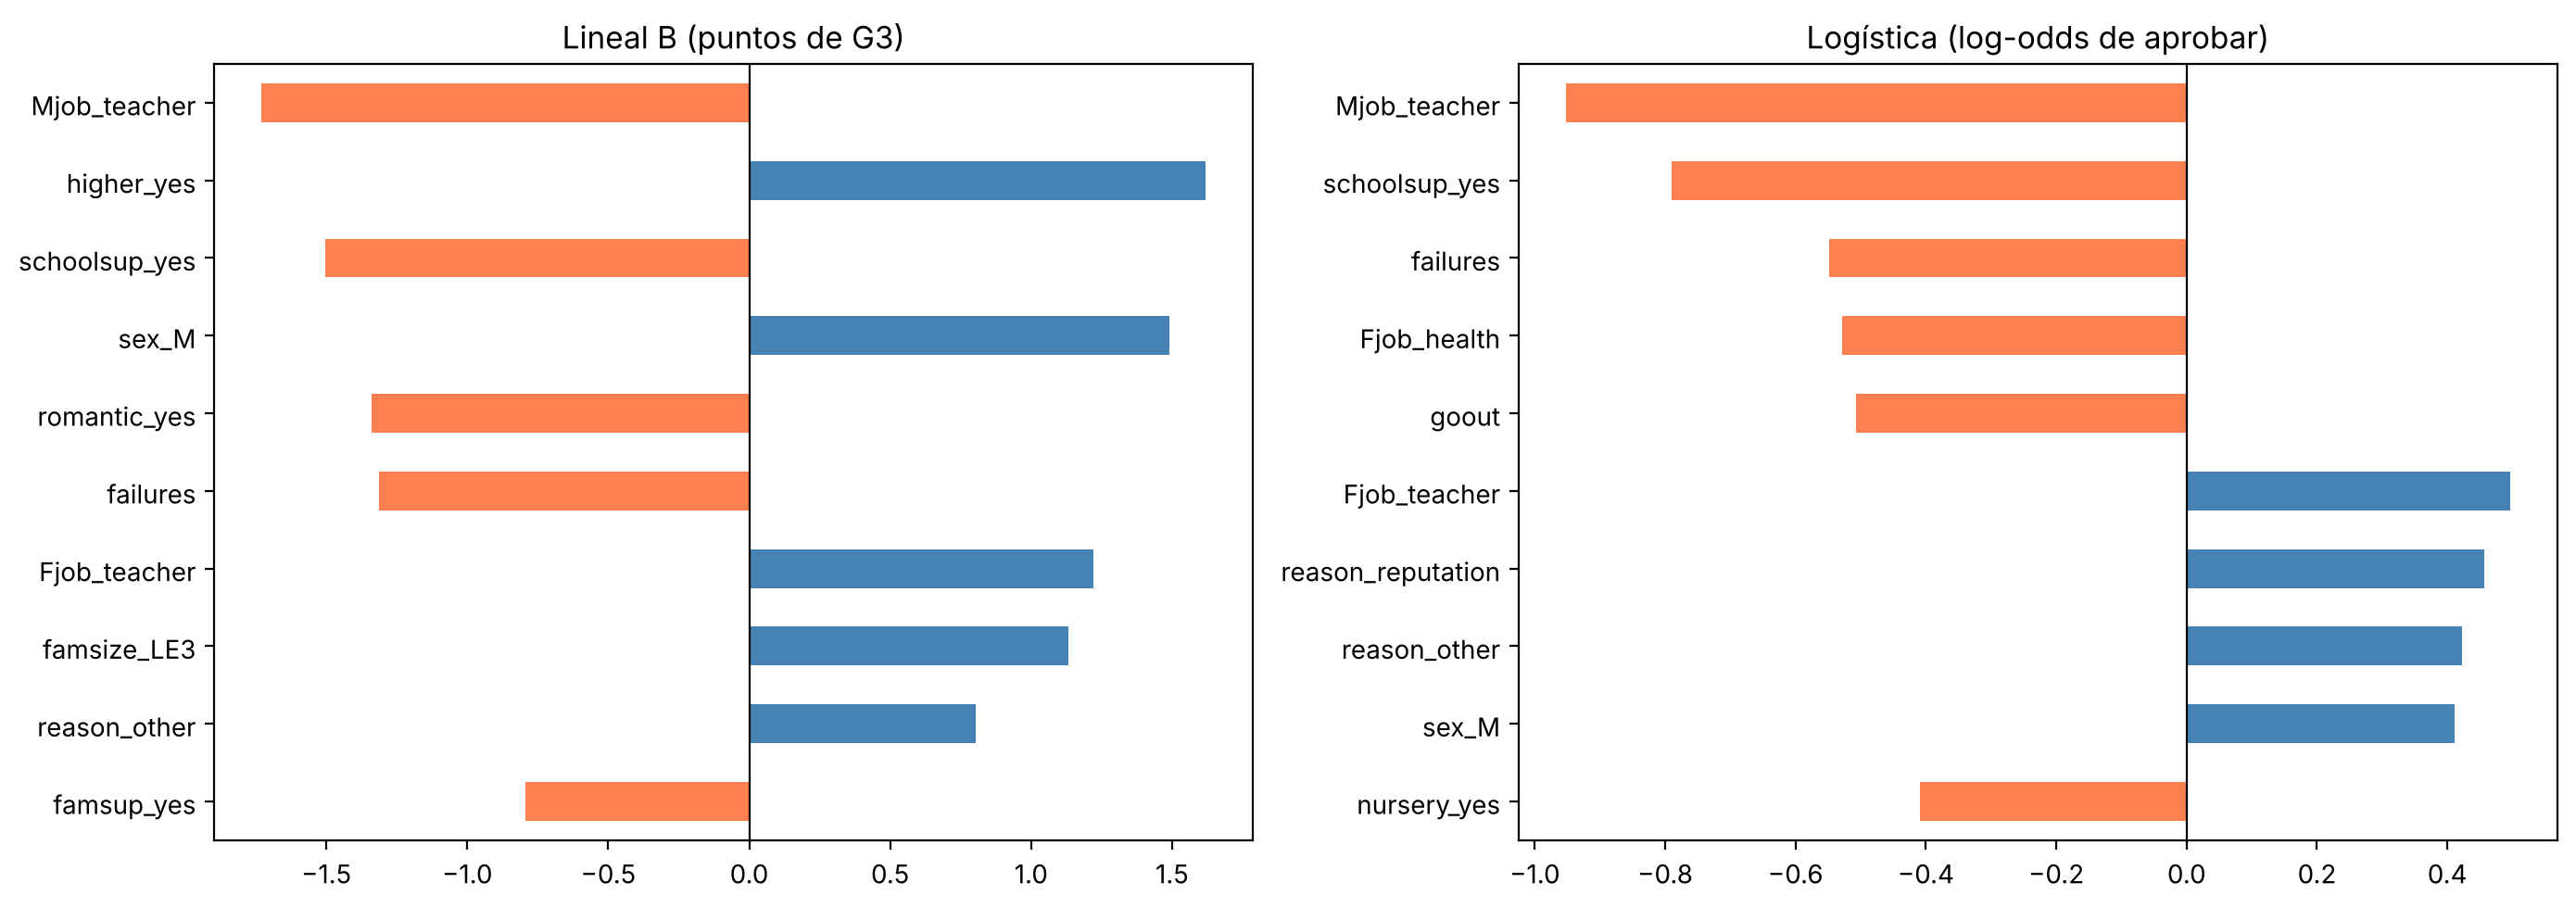

In [9]:
# 5.1 Variables con mayor peso (coeficientes de ambos modelos sin G1/G2)
coef_lin = pd.Series(modelos['B'].named_steps['model'].coef_, index=nombres)
coef_log = pd.Series(logit.named_steps['model'].coef_[0], index=nombres)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, c, t in zip(ax, [coef_lin, coef_log], ['Lineal B (puntos de G3)', 'Logística (log-odds de aprobar)']):
    top = c.loc[c.abs().nlargest(10).index].iloc[::-1]
    top.plot.barh(ax=a, color=np.where(top < 0, 'coral', 'steelblue')); a.set_title(t); a.axvline(0, color='k', lw=.8)
    print(t, '\n', top.iloc[::-1].round(3).to_string(), '\n')
plt.tight_layout(); plt.show()

1. En el Modelo A, las notas previas son la señal principal, en línea con sus altas correlaciones (G2 = 0.905 y G1 = 0.801).
2. Sin esas notas, `failures` destaca de forma consistente: tiene la mayor correlación, pesa en ambos modelos y Lasso la conserva con el mayor coeficiente.
3. También pesan `schoolsup`, el trabajo de la madre (`Mjob_teacher`) y, en la logística, `goout`; en la lineal, `higher` y `sex`.
4. Los coeficientes de dummies se comparan con una categoría de referencia y no son directamente equivalentes a los de variables estandarizadas.
5. Son asociaciones, no causas: el apoyo escolar negativo puede reflejar que se asigna a quienes ya tienen dificultades.
6. Limitaciones: solo 395 estudiantes, dos escuelas, datos antiguos, una asignatura y una sola partición con 79 casos de prueba.
7. Además, varias respuestas son autorreportadas, los residuos no son normales y las notas en 0 no tienen explicación.
8. El Modelo B generaliza muy poco (R² = 0.036) y la logística todavía omite estudiantes en riesgo.
9. **No sería justo negar una beca** con este modelo: se equivoca con frecuencia y usa sexo, familia o alcohol, que pueden reproducir sesgos.
10. Una predicción tampoco mide el mérito ni las necesidades de una persona.
11. Sí podría ser apropiado, como apoyo y después de validarlo, para **priorizar la oferta de tutorías voluntarias**, sin quitar oportunidades a nadie.
12. Recomendamos hacer primero un piloto con datos locales y recientes, revisión humana y acceso a ayuda para quien la solicite.
13. Se deben proteger los datos, informar a estudiantes y familias, permitir reclamos y comparar los errores entre grupos (por ejemplo, por sexo).
14. También conviene evaluar si se pueden retirar las variables sensibles y reentrenar el modelo periódicamente.

## Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito & J. Teixeira (Eds.), *Proceedings of 5th Future Business Technology Conference (FUBUTEC 2008)* (pp. 5–12). EUROSIS.

> **Pendiente del grupo:** agregar en APA 7 las fuentes que realmente hayan consultado en la biblioteca de la Universidad.

## Declaración de uso de inteligencia artificial
Se utilizó Claude (Anthropic) para revisar el notebook frente a la guía, corregir y completar el código, ejecutarlo y redactar un borrador de las interpretaciones y conclusiones. El grupo debe revisar el contenido, redactar las respuestas con sus propias palabras y poder explicar cada línea en la defensa.